# Simple Water Balance Model (SWBM)

[Input time series:]{.underline}

- Precipitation (P)

- Net radiation (R $_{net}$)

[Output time series:]{.underline}

- Soil moisture (w)

- Evapotranspiration (E)

- Runoff (Q)

## Equations
### Water balance w
$$
w_{n+\Delta t} = w_n + (P_n - E_n - Q_n)\Delta t
$$

### Runoff Q
$$
Q_n = (\frac{w_n}{c_s})^\alpha \cdot P_n
$$

### Evapotranspiration E
$$
E_n = \frac{\beta_0(\frac{w_n}{c_s})^\lambda \cdot R_n}{\lambda \rho _w}
$$

## 1. Parameters

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_germany = pd.read_csv('/Users/konstantinczak/Desktop/Msc EnvSc/Courses/Semester 3/Earth System Modelling/Earth-System-Modelling/data/Data_swbm_Germany.csv')
df_germany.head()
ger_precip = df_germany['tp_[mm]']
ger_radiation = df_germany['snr_[MJ/m2]'] / 2.26

In [7]:
# parameters (fixed properties)
params = {
    'c_s': 420, # soil water holding capacity [mm]
    'alpha': 4, # runoff function shape
    'gamma': 0.5, # lambda
    'beta': 0.8, # maximum of ET function
    'rho': 1, # g/cm3
    'lambda': 1
}

# initial soil moisture [mm]
initial_w = 0.9 * params['c_s'] 

# driving data - rainfall and radiation for 4018 days
days = len(ger_precip)
driving_data = {
    'day': np.arange(days),
    'precipitation': ger_precip,
    'radiation': ger_radiation
}

print("Model Components:")
print(f"\nParameters:")
for param, value in params.items():
    print(f"  {param}: {value}")
print(f"\nInitial soil moisture: {initial_w} mm")
print(f"  Precipitation range: {driving_data['precipitation'].min():.1f} mm to {driving_data['precipitation'].max():.1f} mm")
print(f"  Radiation range: {driving_data['radiation'].min():.1f} MJ/m2 to {driving_data['radiation'].max():.1f} MJ/m2")

Model Components:

Parameters:
  c_s: 420
  alpha: 4
  gamma: 0.5
  beta: 0.8
  rho: 1
  lambda: 1

Initial soil moisture: 378.0 mm
  Precipitation range: -0.0 mm to 57.9 mm
  Radiation range: -1.3 MJ/m2 to 8.1 MJ/m2


## 2. Functions

In [4]:
def calculate_runoff(w, precipitation):
    runoff = (w / params['c_s']) ** params['alpha'] * precipitation
    return runoff

def calculate_evapotranspiration(w, radiation):
    evapotranspiration = (params['beta']*(w/params['c_s'])**params['lambda']*radiation)/params['lambda']*params['rho']
    return evapotranspiration

def calculate_waterbalance(precipitation, evapotranspiration, runoff):
    w = precipitation - evapotranspiration - runoff
    return w

## 3. Model loop

In [8]:
# soil moisture
w = np.zeros(days+1)
w[0] = initial_w

# intermediate variables
runoffs = np.zeros(days)
evapotranspirations = np.zeros(days)
ws = np.zeros(days)

# simulation loop
print(f"Day | Prec(mm) | Rad(mm/day) | Runoff (mm) | Evapotrans | deltaWB(mm) | Soil moisture (mm)")
print("-" * 89)

for day in range(days):
    # get driving data
    prec = driving_data['precipitation'][day]
    rad = driving_data['radiation'][day]

    # calculate intermediates
    runoff = calculate_runoff(w[day], prec)
    evapotranspiration = calculate_evapotranspiration(w[day], rad)

    # calculate water balance
    current_w = calculate_waterbalance(prec, evapotranspiration, runoff)

    # update water balance
    w[day + 1] = w[day] + current_w

    # store for analysis
    runoffs[day] = runoff
    evapotranspirations[day] = evapotranspiration
    ws[day] = current_w

    # print selected days
    if day % 100 == 0 or day < 3:
            print(f"{day+1:4d} | {prec:7.1f} | {rad:11.1f} | {runoff:11.3f} | {evapotranspiration:10.3f} | {current_w:11.3f} | {w[day+1]:16.1f}")

print(f"\nSimulation Summary (2008-2018):")
print(f"Starting water balance: {w[0]:.1f} mm")
print(f"Ending water balance: {w[-1]:.1f} mm")
print(f"Total change: {w[-1] - w[0]:.1f} mm")
print(f"Mean daily change: {current_w.mean():.2f} mm")



Day | Prec(mm) | Rad(mm/day) | Runoff (mm) | Evapotrans | deltaWB(mm) | Soil moisture (mm)
-----------------------------------------------------------------------------------------
   1 |     0.0 |        -0.5 |       0.005 |     -0.341 |       0.344 |            378.3
   2 |     0.0 |        -1.0 |       0.002 |     -0.690 |       0.691 |            379.0
   3 |     0.0 |        -0.3 |       0.009 |     -0.200 |       0.204 |            379.2
 101 |     6.6 |         1.3 |       4.289 |      0.910 |       1.419 |            378.3
 201 |     2.3 |         4.9 |       0.574 |      2.763 |      -1.015 |            295.2
 301 |    11.3 |         0.0 |       5.293 |      0.006 |       6.027 |            353.3
 401 |     0.0 |         0.4 |       0.004 |      0.309 |      -0.309 |            422.3
 501 |    11.0 |         2.3 |       3.644 |      1.399 |       5.962 |            324.6
 601 |     0.0 |         5.2 |       0.000 |      2.656 |      -2.656 |            265.1
 701 |     3.8 |  

## 4. Model visualization

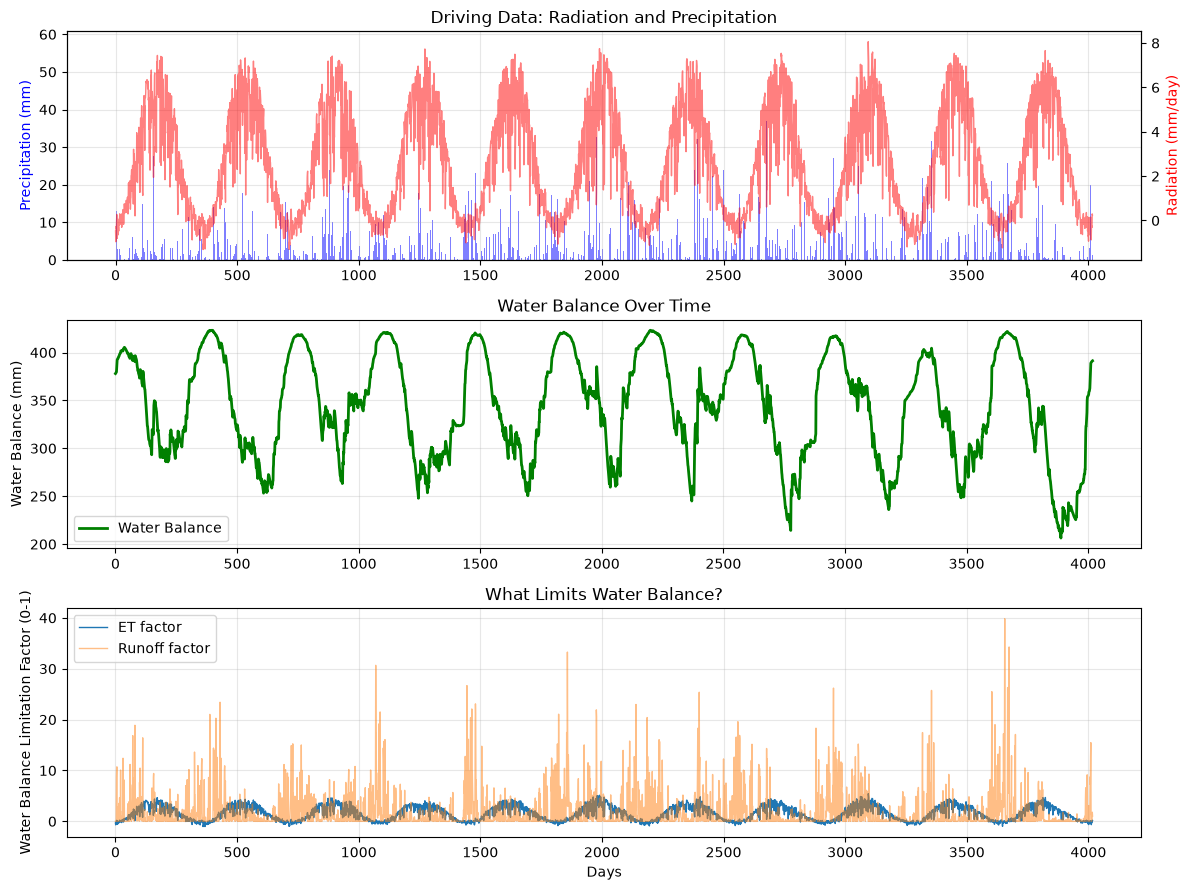

Model outputs visualized!


In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

days_array = np.arange(days + 1)

# Panel 1: Driving data
ax1 = axes[0]
ax1_twin = ax1.twinx()
ax1.bar(days_array[:-1], driving_data['precipitation'], color='blue', alpha=0.5, label='Precipitation')
ax1_twin.plot(days_array[:-1], driving_data['radiation'], color='red', linewidth=1, alpha=0.5, label='Radiation')
ax1.set_ylabel('Precipitation (mm)', color='blue')
ax1_twin.set_ylabel('Radiation (mm/day)', color='red')
ax1.set_title('Driving Data: Radiation and Precipitation')
ax1.grid(alpha=0.3)

# Panel 2: Plant biomass
ax2 = axes[1]
ax2.plot(days_array, w, linewidth=2, color='green', label='Water Balance')
ax2.set_ylabel('Water Balance (mm)')
ax2.set_title('Water Balance Over Time')
ax2.legend()
ax2.grid(alpha=0.3)

# Panel 3: Limiting factors
ax3 = axes[2]
ax3.plot(days_array[:-1], evapotranspirations, label='ET factor', linewidth=1)
ax3.plot(days_array[:-1], runoffs, label='Runoff factor', linewidth=1, alpha = 0.5)
ax3.set_xlabel('Days')
ax3.set_ylabel('Water Balance Limitation Factor (0-1)')
ax3.set_title('What Limits Water Balance?')
ax3.legend()
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Model outputs visualized!")